# 07 - Price & Coal-Quality Analysis

How prices and coal quality moved, and how price relates to quality. Uses U.S. Total rows for sector prices (state IPP prices are sparse).

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data
from src.taxonomy import add_location_level, filter_location, SECTOR_DESCRIPTIONS
from src.clean import clean
df = add_location_level(clean(load_coal_data(DATA)))
us = filter_location(df, 'national')

In [4]:
# Price by sector (sectors that report a price at US level)
price_sectors = [1, 9, 10, 3]
lab = {1: 'Electric Utility', 9: 'Coke Plants', 10: 'Other Industrial', 3: 'IPP CHP'}
pp = us[us['sector'].isin(price_sectors)].copy()
ppiv = pp.pivot_table(index='period', columns='sector', values='price', aggfunc='mean')
ppiv = ppiv[price_sectors]
ppiv.columns = [lab[c] for c in ppiv.columns]
ppiv.round(2)

,Electric Utility,Coke Plants,Other Industrial,IPP CHP
period,,,,
2020,37.49,127.16,57.18,47.67
2021,NaN,122.37,57.89,NaN
2022,45.96,195.61,69.76,50.66
2023,48.88,211.60,83.39,52.57
2024,48.93,189.68,78.04,33.36
2025,47.79,183.43,76.43,45.35


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\07_price_by_sector.png


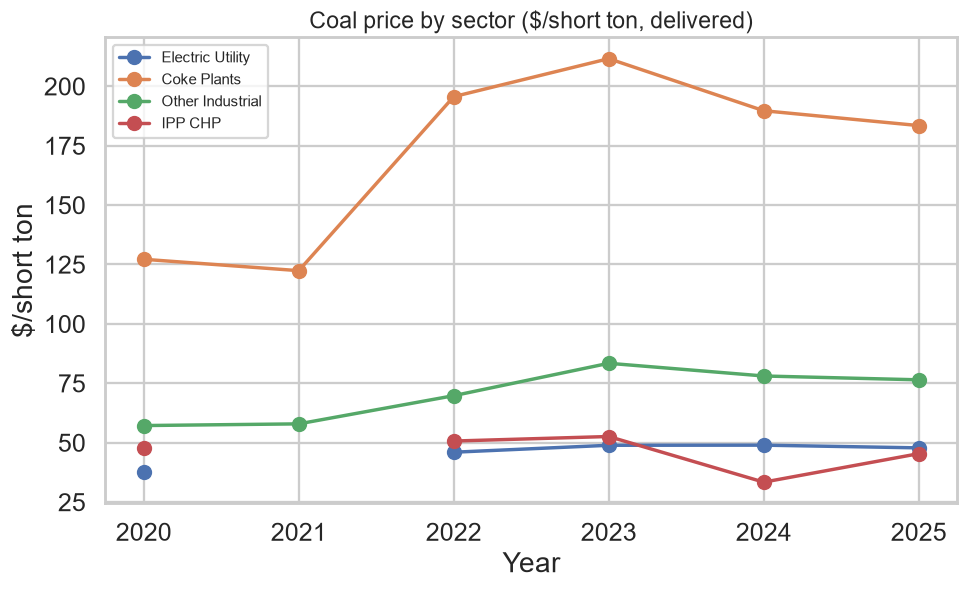

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for c in ppiv.columns:
    ax.plot(ppiv.index, ppiv[c], marker='o', label=c)
ax.set_title('Coal price by sector ($/short ton, delivered)', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('$/short ton'); ax.legend(fontsize=10)
savefig('07_price_by_sector.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\07_price_vs_heat_content.png


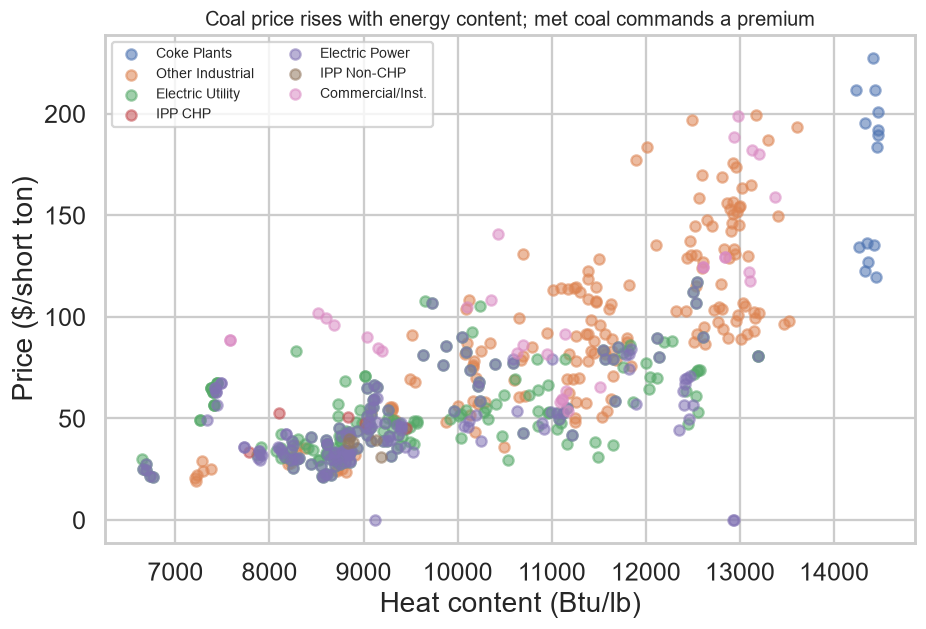

In [6]:
# Price vs heat content (all rows with both present), colored by end use
sc = df[(df['price'].notna()) & (df['heat_content_btu_lb'] > 0)].copy()
sc['enduse'] = sc['sector'].map({1:'Electric Utility',2:'IPP Non-CHP',3:'IPP CHP',
    8:'Commercial/Inst.',9:'Coke Plants',10:'Other Industrial',98:'Electric Power',94:'IPP'})
fig, ax = plt.subplots(figsize=(9.5, 6))
for eu, col in [('Coke Plants','#c44e52'),('Other Industrial','#dd8452'),
                ('Electric Utility','#4c72b0'),('IPP CHP','#55a868'),
                ('Electric Power','#8172b3'),('IPP Non-CHP','#937860'),('Commercial/Inst.','gray')]:
    d = sc[sc['enduse'] == eu]
    if len(d):
        ax.scatter(d['heat_content_btu_lb'], d['price'], label=eu, alpha=0.55, s=45)
ax.set_title('Coal price rises with energy content; met coal commands a premium', fontsize=13)
ax.set_xlabel('Heat content (Btu/lb)'); ax.set_ylabel('Price ($/short ton)')
ax.legend(fontsize=9, ncol=2)
savefig('07_price_vs_heat_content.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\07_sulfur_trend.png


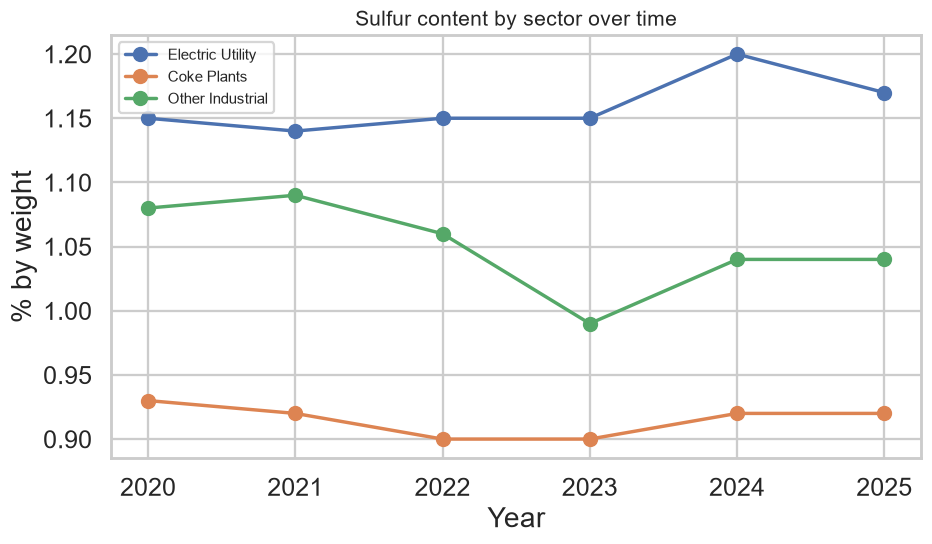

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\07_ash_trend.png


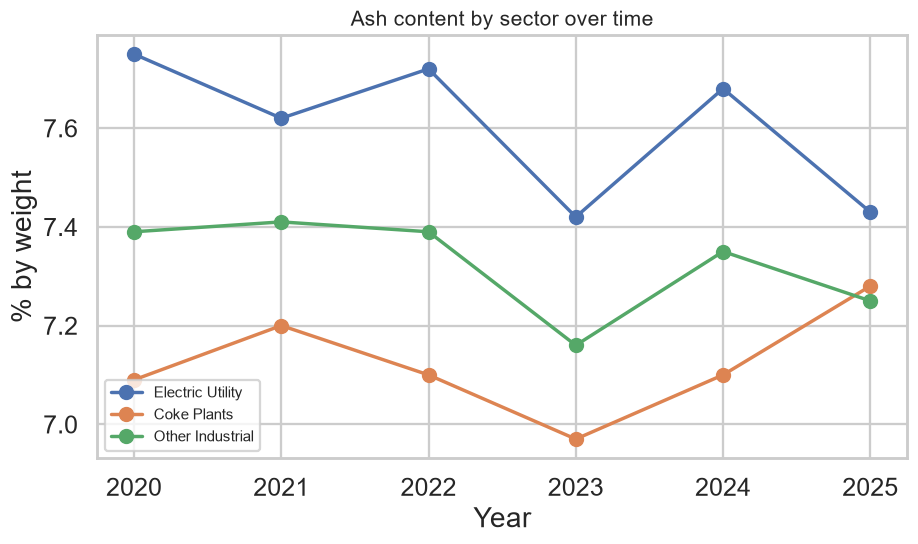

In [7]:
# Quality trends: sulfur & ash by sector over time (US total, key sectors)
qs = us[us['sector'].isin([1, 9, 10])].copy()
for col, title in [('sulfur-content','Sulfur content'), ('ash-content','Ash content')]:
    p = qs.pivot_table(index='period', columns='sector', values=col, aggfunc='mean')
    p = p[[1,9,10]]; p.columns=[lab[c] for c in p.columns]
    fig, ax = plt.subplots(figsize=(9.5,5))
    for c in p.columns:
        ax.plot(p.index, p[c], marker='o', label=c)
    ax.set_title(f'{title} by sector over time', fontsize=14)
    ax.set_xlabel('Year'); ax.set_ylabel('% by weight'); ax.legend(fontsize=10)
    savefig(f'07_{col.split("-")[0]}_trend.png')

In [8]:
# Validation: coke/met-coal price is genuinely high (not an error); flag only extreme outliers
prices = us['price'].dropna()
assert prices.max() < 500, 'unexpected price outlier'
corr = sc[['price','heat_content_btu_lb']].corr().iloc[0,1]
print('price-heat-content correlation:', round(corr, 2))
print('max price ($/ton):', round(prices.max(), 1), '(coke/met coal premium is real)')

price-heat-content correlation: 0.72
max price ($/ton): 211.6 (coke/met coal premium is real)


**Takeaways**
- Coke/met-coal is priced far above power coal (~$120-200/ton vs ~$30-60/ton), and price rises with heat content - higher-energy coal is worth more.
- Sulfur and ash differ by sector; quality trends show whether the coal being burned is getting cleaner or dirtier over time.
- The price-heat-content relationship confirms met-coal's premium value.